<a href="https://colab.research.google.com/github/FabianJerez/TP1/blob/master/5_CIA_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 5 · Guía de trabajo en equipo — Correlación (Pearson vs. Spearman) y heatmap


> **¿Dónde estamos en el flujo del EDA?**
> En el análisis bivariado **vimos** relaciones con gráficos de dispersión. Ahora vamos a **medirlas con un número**: el **coeficiente de correlación**. Seguimos en el paso **05 – Explorar y analizar** (correlaciones).
> Teoría relacionada: láminas *"Tipos de correlación"*, *"La correlación no implica causalidad"* y *"Valores atípicos"*.

> **Pregunta guía del análisis (la misma de los notebooks 0 y 1):**
> ¿Qué características de las células parecen diferenciar un tumor **maligno** (`target = 0`) de uno **benigno** (`target = 1`)?

> **Cómo trabajar**
> 1. Hagan una copia del notebook (*Archivo → Guardar una copia en Drive*) y suban `sample_dataset.csv` al panel **Archivos** (ícono de carpeta, a la izquierda).
> 2. Ejecuten las celdas **en orden** (Shift + Enter).
> 3. Lean los cuadros 📘, completen las celdas 🧩 (reemplazar cada `COMPLETAR`) y respondan en las celdas ✍️.
>    Las celdas 🧩 **dan error hasta que reemplacen `COMPLETAR`**: es esperable, no es un problema del notebook.
> 4. Al final, armen la sección 🎤: **cada equipo va a explicar su notebook al resto del curso en 5 minutos.**
>
> | Ícono | Significa |
> |---|---|
> | 📘 | Concepto (relacionado con la teoría vista) |
> | 💻 | Código listo para ejecutar y observar |
> | 🧩 | Código para completar (reemplazar `COMPLETAR`) |
> | ✍️ | Pregunta para responder en equipo |
> | ⭐ | Extra, solo si les sobra tiempo |
> | 🎤 | Lo que van a presentar al resto |

## 0) Preparación

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
# Cada notebook es independiente: hay que volver a importar librerías y cargar los datos.
# Si aparece FileNotFoundError: el CSV no está subido en el panel "Archivos" de ESTE notebook.
df = pd.read_csv("sample_dataset.csv")
df.shape   # esperamos (569, 31)

(569, 31)

## 1) El coeficiente de correlación

📘 **Concepto.** El coeficiente de correlación **r** resume en un número **la dirección y la fuerza** de la relación entre dos variables numéricas:

| Valor de r | Interpretación |
|---|---|
| r = 1 | positiva **perfecta** |
| r ≈ 0,7 a 0,99 | positiva **fuerte** |
| r ≈ 0,3 a 0,7 | positiva **moderada** |
| r ≈ 0 | **nula** (sin relación *lineal*) |
| r negativos | lo mismo, pero la relación es **negativa** (una sube, la otra baja) |

*Los cortes son orientativos: dependen del área de estudio.*

In [14]:
# Correlación entre dos columnas (los NaN se ignoran de a pares)
r1 = df["mean perimeter"].corr(df["mean area"])
print(f"mean perimeter vs mean area: r = {r1:.2f}")

mean perimeter vs mean area: r = 0.98


🧩 **Completen** para calcular la correlación entre `mean radius` y `mean smoothness`.

In [15]:
r2 = df["mean radius"].corr(df["mean smoothness"])
print(f"mean radius vs mean smoothness: r = {r2:.2f}")

mean radius vs mean smoothness: r = 0.17


✍️ **Pregunta:** Usando la tabla, ¿cómo clasifican cada una de las dos correlaciones?

✍️ **Respuesta del equipo:**

1. La correlacion entre mean perimeter y mean area (0.98) es positiva fuerte.
2. La correlacion entre mean radius y mean smoothness (0.17) es nula.

## 2) La matriz de correlación

💻 `df.corr()` calcula la correlación **de todas las variables contra todas**.

> **Ojo (pandas 2.x, la versión de Colab):** si el DataFrame tiene columnas de texto (como `area error`), `df.corr()` da **error**. Por eso agregamos `numeric_only=True`, que usa solo las columnas numéricas.

In [ ]:
corr = df.corr(numeric_only=True)
corr.round(2)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
mean radius,1.00,0.33,1.00,0.99,0.17,0.54,0.67,0.82,0.13,-0.30,...,0.34,0.96,0.94,0.15,0.47,0.54,0.76,0.16,0.01,-0.73
mean texture,0.33,1.00,0.35,0.33,-0.03,0.19,0.27,0.32,0.05,-0.08,...,0.91,0.37,0.36,0.09,0.25,0.28,0.29,0.12,0.13,-0.40
mean perimeter,1.00,0.35,1.00,0.98,0.22,0.54,0.70,0.84,0.18,-0.26,...,0.35,0.97,0.94,0.15,0.46,0.56,0.77,0.21,0.05,-0.75
mean area,0.99,0.33,0.98,1.00,0.24,0.51,0.69,0.83,0.23,-0.26,...,0.32,0.96,0.96,0.16,0.38,0.51,0.71,0.14,-0.00,-0.71
mean smoothness,0.17,-0.03,0.22,0.24,1.00,0.66,0.51,0.55,0.54,0.61,...,-0.07,0.27,0.20,0.80,0.50,0.42,0.50,0.40,0.54,-0.35
mean compactness,0.54,0.19,0.54,0.51,0.66,1.00,0.88,0.82,0.62,0.56,...,0.18,0.60,0.51,0.55,0.87,0.81,0.81,0.54,0.69,-0.60
mean concavity,0.67,0.27,0.70,0.69,0.51,0.88,1.00,0.92,0.55,0.37,...,0.29,0.73,0.67,0.45,0.75,0.88,0.85,0.42,0.54,-0.67
mean concave points,0.82,0.32,0.84,0.83,0.55,0.82,0.92,1.00,0.48,0.14,...,0.33,0.86,0.81,0.47,0.69,0.77,0.91,0.40,0.37,-0.77
mean symmetry,0.13,0.05,0.18,0.23,0.54,0.62,0.55,0.48,1.00,0.50,...,0.05,0.23,0.20,0.43,0.52,0.45,0.44,0.73,0.51,-0.34
mean fractal dimension,-0.30,-0.08,-0.26,-0.26,0.61,0.56,0.37,0.14,0.50,1.00,...,-0.09,-0.20,-0.22,0.53,0.47,0.33,0.18,0.40,0.78,-0.00


✍️ **Pregunta:** ¿Por qué la diagonal está llena de 1? ¿Por qué la matriz es simétrica? ¿Es fácil sacar conclusiones mirando esta tabla?

✍️ **Respuesta del equipo:**

1. La diaggonal principal esta llena de 1 por que se compara la misma variable.
2. La matriz es simetrica por que se comparan el mismo par de variables.
3. La tabla permite sacar conclusiones facilmente.

## 3) Pearson vs. Spearman

📘 **Concepto.** Por defecto, `corr()` calcula el coeficiente de **Pearson**. Hay otro muy usado: **Spearman**.

| Característica | **Pearson** | **Spearman** |
|---|---|---|
| Mide relaciones... | **lineales** (línea recta) | **monótonas** (siempre crece o siempre decrece, aunque sea en curva) |
| Se calcula sobre... | los valores originales | los **rangos** (posiciones al ordenar los datos: 1°, 2°, 3°...) |
| Sensibilidad a outliers | **alta** | **baja** |
| Supone distribución aprox. normal | sí | no |
| Uso típico | altura vs. peso | ranking de satisfacción vs. edad; datos asimétricos u ordinales |

**Idea clave:** como Spearman trabaja con posiciones, un valor extremo es "solo el primero de la fila", no un número gigante que arrastra el cálculo.

In [17]:
corr_p = df.corr(method="pearson", numeric_only=True)
corr_s = df.corr(method="spearman", numeric_only=True)

for a, b in [("mean radius", "mean area"), ("mean concavity", "mean area"), ("radius error", "mean radius")]:
    print(f"{a:>15} vs {b:<12}  Pearson = {corr_p.loc[a, b]:.2f} | Spearman = {corr_s.loc[a, b]:.2f}")

    mean radius vs mean area     Pearson = 0.99 | Spearman = 1.00
 mean concavity vs mean area     Pearson = 0.69 | Spearman = 0.65
   radius error vs mean radius   Pearson = 0.68 | Spearman = 0.51


## 4) Heatmap: la matriz de correlación en colores

📘 **Concepto.** Un **heatmap** (mapa de calor) pinta cada celda de una matriz según su valor. Con la paleta `coolwarm` y la escala fija entre -1 y 1:
- **Rojo intenso** → correlación positiva fuerte
- **Azul intenso** → correlación negativa fuerte
- **Blanco / gris claro** → cerca de 0, sin relación lineal

`annot=True` escribe el valor dentro de cada celda (útil con pocas variables).

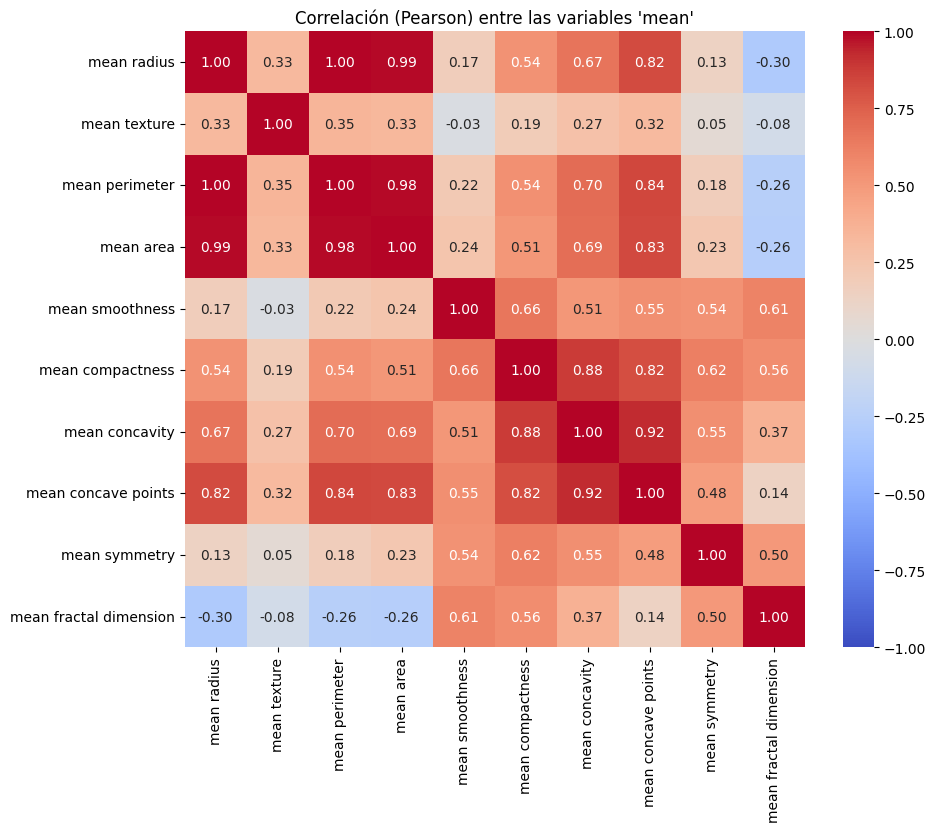

In [18]:
cols_mean = [c for c in df.columns if c.startswith("mean")]   # solo las 10 variables "mean ..."

plt.figure(figsize=(10, 8))
sns.heatmap(df[cols_mean].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación (Pearson) entre las variables 'mean'")
plt.show()

✍️ **Preguntas**
1. ¿Qué pares tienen correlación **mayor a 0,9**? ¿Forman "grupos" o "familias" de variables?
2. ¿Hay alguna correlación **negativa** que se destaque?

✍️ **Respuesta del equipo:**

1. Pares mayores a 0.9: mean radius mean area, mean perimeter mean area, mean concavity mean concave points.
Las primeras dos forman el grupo geometrico del ciculo (perimetro, area y radio) y la ultima el grupo de concavidad.
2. No hay ninguna correlacion negativa que destaque.

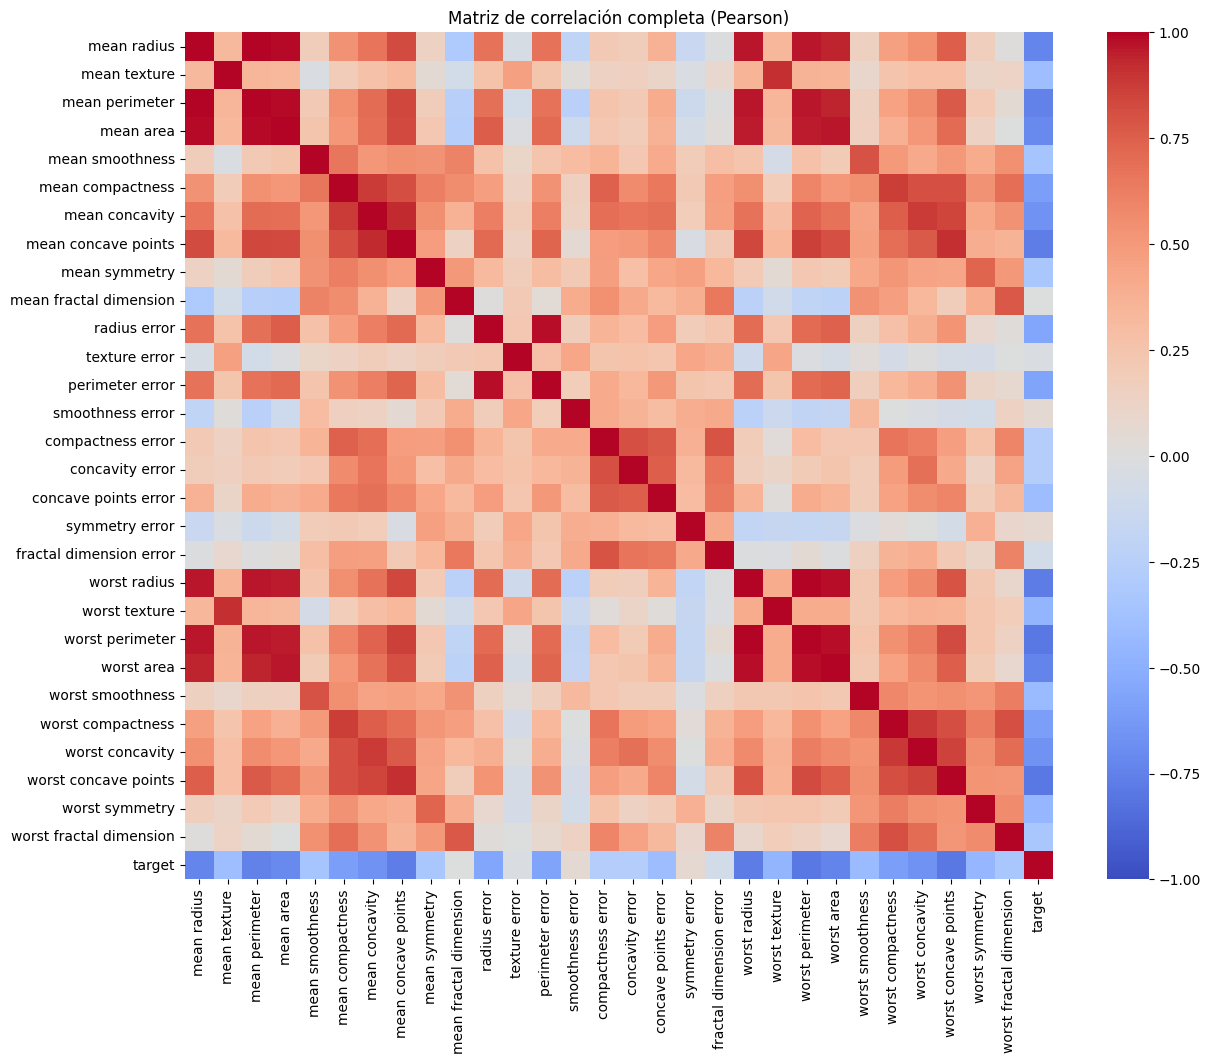

In [19]:
# Todas las variables numéricas (sin números: con 30 variables no se leerían)
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación completa (Pearson)")
plt.show()

💻 **Heatmap en valor absoluto.** Si nos interesa solo la **intensidad** de la correlación (sin importar si es positiva o negativa), graficamos el valor absoluto: así una correlación de -0,8 y una de 0,8 se ven igual de "fuertes".

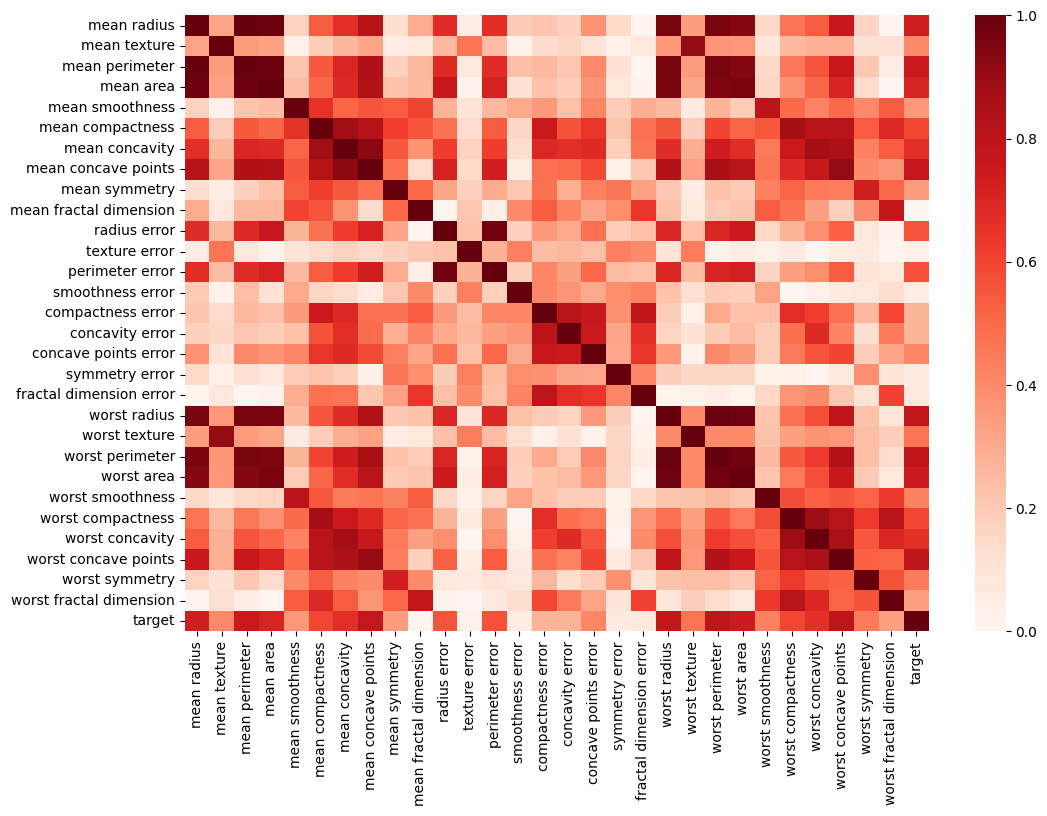

In [ ]:
#Si nos interesa solo la intensidad de la correlación, podemos graficar con el valor absoluto
plt.figure(figsize=(12,8))
sns.heatmap(corr.abs(), cmap="Reds", vmin=0, vmax=1)
plt.show()

✍️ **Pregunta:** ¿Qué ganamos y qué perdemos al usar el valor absoluto?

✍️ **Respuesta del equipo:**

1. Podemos ver con mas claridad la intensidad del color con lo cual vemos facilmente cuales son las variables que estan fuertemente relacionadas ya sea positiva o negativa.
2. A su vez perdemos la direccion, es decir si la relacion entre las variables es positiva o negativa.

## 5) Volvamos a la pregunta guía: ¿qué variables se relacionan más con el diagnóstico?

📘 **Ojo con el signo.** `target` vale **0 = maligno** y **1 = benigno**. Entonces:
- correlación **negativa** con `target` → cuando la variable **sube**, es más probable que sea **maligno**;
- correlación **positiva** → valores altos se asocian a **benigno**.

*(`target` es binaria, así que esta correlación se usa como una medida **orientativa** de asociación.)*

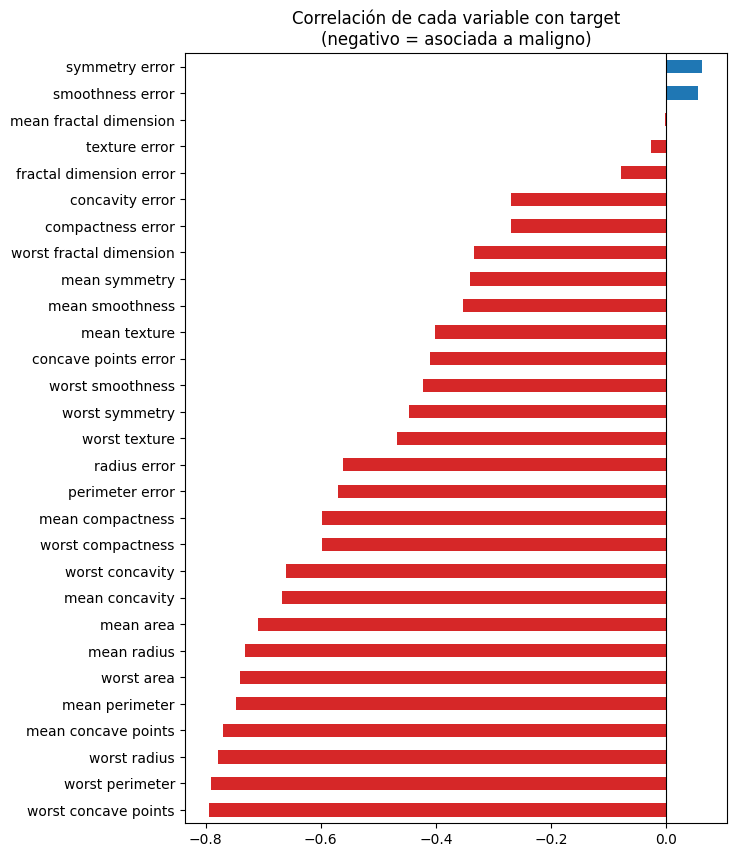

,target
worst concave points,-0.79
worst perimeter,-0.79
worst radius,-0.78
mean concave points,-0.77
mean perimeter,-0.75
worst area,-0.74
mean radius,-0.73
mean area,-0.71
mean concavity,-0.67
worst concavity,-0.66


In [20]:
corr_target = corr["target"].drop("target").sort_values()

corr_target.plot(kind="barh", figsize=(7, 10), color=np.where(corr_target < 0, "tab:red", "tab:blue"))
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlación de cada variable con target\n(negativo = asociada a maligno)")
plt.show()

corr_target.head(10).round(2)

## 6) Para pensar: dos advertencias

📘 1) **Correlación no implica causalidad.** 2) **Los outliers pueden cambiar mucho el valor de r** (lámina: un mismo conjunto puede dar r = 0,2 con outliers y r = 0,8 sin ellos).

✍️ **Pregunta:** `worst concave points` tiene una correlación fuerte con el diagnóstico. ¿Podemos decir que los puntos cóncavos **causan** el cáncer? ¿Cómo lo dirían correctamente en un informe?

✍️ **Respuesta del equipo:**

1. no podemos afirmar que los puntos concavos causan el cancer, ya que correlacion no implica causalidad. A lo sumo es un sintoma o indicador pero no la causa biologica de la enfermedad.
2. En un informe podrimos decir: Segun los analisis la variable "worst concave points" es una de las que mas se correlaciona con el "target" =0 es decir maligno, con lo cual es una de las variables mas importante para el estudio por su naturalez predictiva.